Start by loading the `tidymodels` package...

In [1]:
library(tidymodels)
library(vip)

── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──



✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 



── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ purrr::discard() masks scales::discard()
✖ dplyr::filter()  masks stats::filter()
✖ dplyr::lag()     masks stats::lag()
✖ recipes::step()  masks stats::step()




Attaching package: ‘vip’




The following object is masked from ‘package:utils’:

    vi




Let's work with [hotel bookings data](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md) from TidyTuesday. 

In [2]:
hotels = 
  readr::read_csv("https://tidymodels.org/start/case-study/hotels.csv", col_types = readr::cols()) |>
  mutate(across(where(is.character), as.factor)) # turns all categorical columns into factors

hotels |> head()

hotel,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,meal,country,market_segment,distribution_channel,⋯,reserved_room_type,assigned_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,average_daily_rate,required_car_parking_spaces,total_of_special_requests,arrival_date
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>,⋯,<fct>,<fct>,<dbl>,<fct>,<dbl>,<fct>,<dbl>,<fct>,<dbl>,<date>
City_Hotel,217,1,3,2,none,BB,DEU,Offline_TA/TO,TA/TO,⋯,A,A,0,No_Deposit,0,Transient-Party,80.75,none,1,2016-09-01
City_Hotel,2,0,1,2,none,BB,PRT,Direct,Direct,⋯,D,K,0,No_Deposit,0,Transient,170.00,none,3,2017-08-25
Resort_Hotel,95,2,5,2,none,BB,GBR,Online_TA,TA/TO,⋯,A,A,2,No_Deposit,0,Transient,8.00,none,2,2016-11-19
Resort_Hotel,143,2,6,2,none,HB,ROU,Online_TA,TA/TO,⋯,A,A,0,No_Deposit,0,Transient,81.00,none,1,2016-04-26
Resort_Hotel,136,1,4,2,none,HB,PRT,Direct,Direct,⋯,F,F,0,No_Deposit,0,Transient,157.60,none,4,2016-12-28
City_Hotel,67,2,2,2,none,SC,GBR,Online_TA,TA/TO,⋯,A,A,0,No_Deposit,0,Transient,49.09,none,1,2016-03-13


Each row is a "stay" and we want to predict whether the stay included children given the other features.

We'll want to extract a bit more information from the `arrival_date` column. So, let's make a `recipe`.

In [3]:
rec = recipe(children ~ ., data = hotels) |>
    step_date(arrival_date) |>
    step_holiday(arrival_date) |>
    step_rm(arrival_date) |>
    prep()

What does this recipe do? Look at the transformed data with "juice".

In [4]:
rec = recipe(children ~ ., data = hotels) |>
  step_date(arrival_date) |>
  step_holiday(arrival_date) |>
  step_rm(arrival_date) |>
  prep()

rec |> juice()

hotel,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,meal,country,market_segment,distribution_channel,is_repeated_guest,⋯,average_daily_rate,required_car_parking_spaces,total_of_special_requests,children,arrival_date_dow,arrival_date_month,arrival_date_year,arrival_date_LaborDay,arrival_date_NewYearsDay,arrival_date_ChristmasDay
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<dbl>,⋯,<dbl>,<fct>,<dbl>,<fct>,<fct>,<fct>,<int>,<int>,<int>,<int>
City_Hotel,217,1,3,2,BB,DEU,Offline_TA/TO,TA/TO,0,⋯,80.75,none,1,none,Thu,Sep,2016,0,0,0
City_Hotel,2,0,1,2,BB,PRT,Direct,Direct,0,⋯,170.00,none,3,none,Fri,Aug,2017,0,0,0
Resort_Hotel,95,2,5,2,BB,GBR,Online_TA,TA/TO,0,⋯,8.00,none,2,none,Sat,Nov,2016,0,0,0
Resort_Hotel,143,2,6,2,HB,ROU,Online_TA,TA/TO,0,⋯,81.00,none,1,none,Tue,Apr,2016,0,0,0
Resort_Hotel,136,1,4,2,HB,PRT,Direct,Direct,0,⋯,157.60,none,4,none,Wed,Dec,2016,0,0,0
City_Hotel,67,2,2,2,SC,GBR,Online_TA,TA/TO,0,⋯,49.09,none,1,none,Sun,Mar,2016,0,0,0
Resort_Hotel,47,0,2,2,BB,ESP,Direct,Direct,0,⋯,289.00,none,1,children,Wed,Aug,2017,0,0,0
City_Hotel,56,0,3,0,BB,ESP,Online_TA,TA/TO,0,⋯,82.44,none,1,children,Thu,Dec,2016,0,0,0
City_Hotel,80,0,4,2,BB,FRA,Online_TA,TA/TO,0,⋯,135.00,none,1,none,Tue,May,2017,0,0,0


Let's start with a decision tree. 

In [5]:
mod = decision_tree() |>
    set_engine('rpart') |>
    set_mode('classification')

Fit `mod` using the data from your prepped recipe. (Hint: remember `juice`).

In [6]:
mod_fit = mod |>
  fit(children ~ ., data = rec |> juice())

Use the snippet below to visualize the tree. What is the first split?

```r
rpart.plot::rpart.plot(mod_fit$fit)
```

Warning message:
“Cannot retrieve the data used to build the model (so cannot determine roundint and is.binary for the variables).
To silence this warning:
    Call rpart.plot with roundint=FALSE,
    or rebuild the rpart model with model=TRUE.”


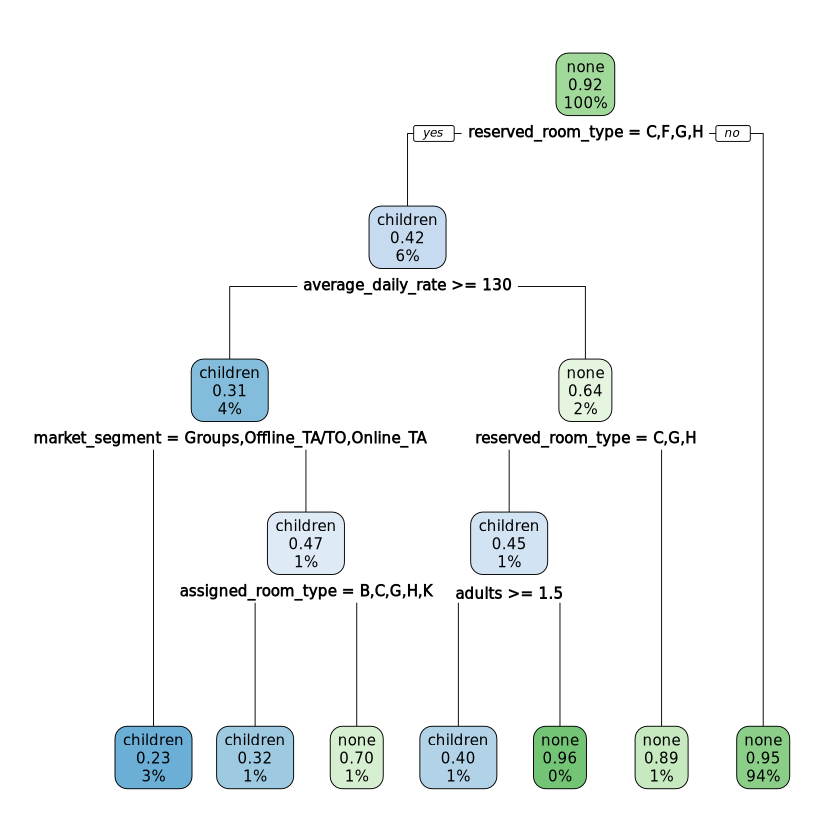

In [7]:
rpart.plot::rpart.plot(mod_fit$fit)

Now create a `random_forest` model and fit it to the transformed `hotels` data.

1. the `mode` should be "classification", and,
2. add `importance = "impurity"` to `set_engine` so we can calculate feature importances with the model.

In [8]:
rf_mod =
  rand_forest() |>
  set_engine("ranger", importance = "impurity") |>
  set_mode("classification")

rf_fit =
  rf_mod |>
  fit(children ~ ., data = rec |> juice())

rf_fit

parsnip model object

Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, importance = "impurity",      num.threads = 1, verbose = FALSE, seed = sample.int(10^5,          1), probability = TRUE) 

Type:                             Probability estimation 
Number of trees:                  500 
Sample size:                      50000 
Number of independent variables:  27 
Mtry:                             5 
Target node size:                 10 
Variable importance mode:         impurity 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.04206349 

We can plot the feature importances. Pipe your fitted model into `extract_fit_engine()` and then into `vip(num_features = 20)`.

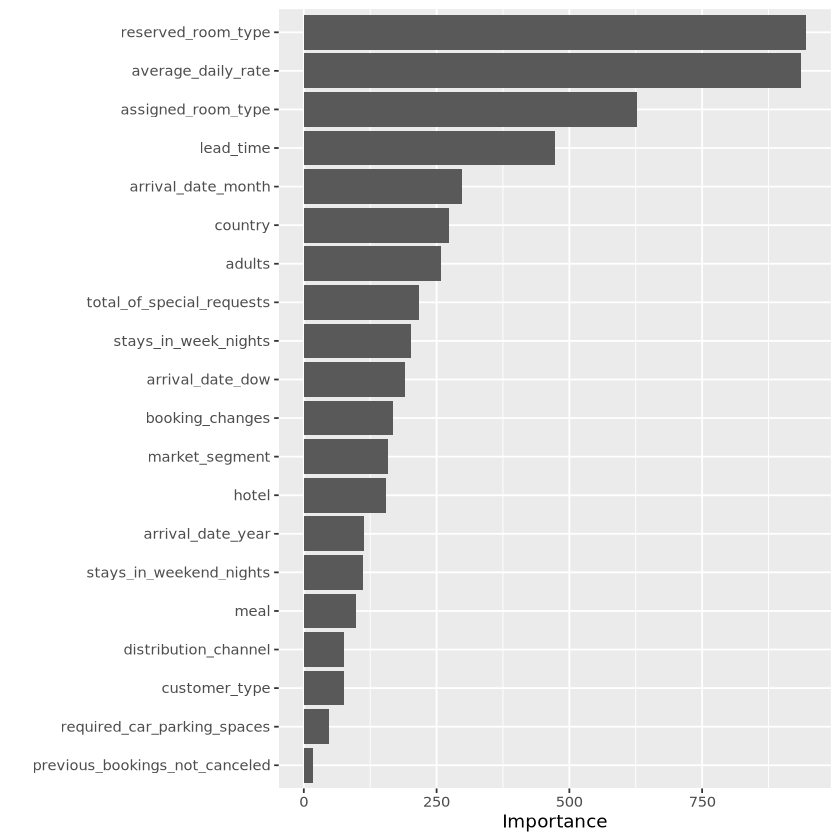

In [9]:
rf_fit |>
  extract_fit_engine() |>
  vip(num_features = 20)